In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

DATA = Path("../data")

BLUE, ORANGE, INK, MUTED, GRID, SURF = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e3e2dd", "#fcfcfb"
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
SEQ = LinearSegmentedColormap.from_list("blue_seq", ["#eaf2fb", BLUE, "#0f3a6e"])
DIV = LinearSegmentedColormap.from_list("div", [BLUE, "#e3e2dd", ORANGE])

VN = {
    "TB": "Tây Bắc", "DB": "Đông Bắc", "DBSH": "ĐB sông Hồng", "BTB": "Bắc Trung Bộ",
    "NTB": "Nam Trung Bộ", "TN": "Tây Nguyên", "DNB": "Đông Nam Bộ", "DBSCL": "ĐB sông Cửu Long",
}
FOREST = ["TB", "DB", "BTB", "NTB", "TN", "DNB"]
ALL_REGIONS = FOREST + ["DBSH", "DBSCL"]

df = pd.read_csv(DATA / "clean" / "panel_clean.csv", parse_dates=["date"])
print("Bảng sạch:", df.shape, "| tỉnh:", df["prov"].nunique(), "| ngày:", df["date"].min().date(), "->", df["date"].max().date())
df[["fire_any_forest", "large_event_active", "n_hot_forest", "n_hot_all", "T13", "D13_hpa", "rain_cal", "P_primary"]].describe().T.round(2)

Bảng sạch: (273209, 67) | tỉnh: 63 | ngày: 2012-01-20 -> 2024-03-31


,count,mean,std,min,25%,50%,75%,max
fire_any_forest,273209.0,0.21,0.41,0.0,0.00,0.00,0.00,1.00
large_event_active,273209.0,0.09,0.28,0.0,0.00,0.00,0.00,1.00
n_hot_forest,273209.0,1.58,7.58,0.0,0.00,0.00,0.00,319.00
n_hot_all,273209.0,2.84,12.61,0.0,0.00,0.00,1.00,553.00
T13,273209.0,28.56,4.89,2.3,26.10,29.60,31.90,40.90
D13_hpa,273209.0,13.56,7.27,0.0,8.08,12.84,18.02,51.56
rain_cal,273209.0,5.51,10.31,0.0,0.00,1.60,7.20,315.80
P_primary,273209.0,2265.69,5488.27,0.0,0.00,308.63,1746.60,56931.00


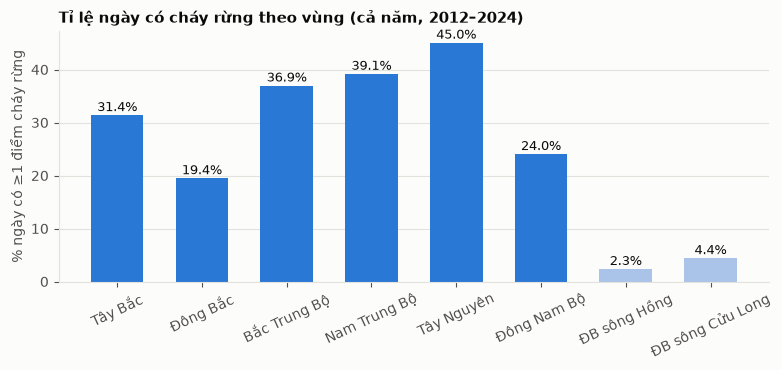

In [2]:
rate = df.groupby("region")["fire_any_forest"].mean().reindex(ALL_REGIONS) * 100

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar([VN[k] for k in rate.index], rate.values, color=[BLUE if k in FOREST else "#a9c4e8" for k in rate.index], width=0.62)
for bar, value in zip(bars, rate.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.8, f"{value:.1f}%", ha="center", color=INK, fontsize=9)
ax.set_ylabel("% ngày có ≥1 điểm cháy rừng")
ax.set_title("Tỉ lệ ngày có cháy rừng theo vùng (cả năm, 2012–2024)")
ax.tick_params(axis="x", labelrotation=25)
ax.grid(axis="x", visible=False)
plt.tight_layout()

Sáu vùng có rừng (xanh đậm) có tỉ lệ ngày cháy cao hơn hẳn hai đồng bằng (xanh nhạt).

Tổng điểm cháy rừng trong bảng dev: 432011
15 tỉnh đầu chiếm 76% tổng điểm cháy rừng


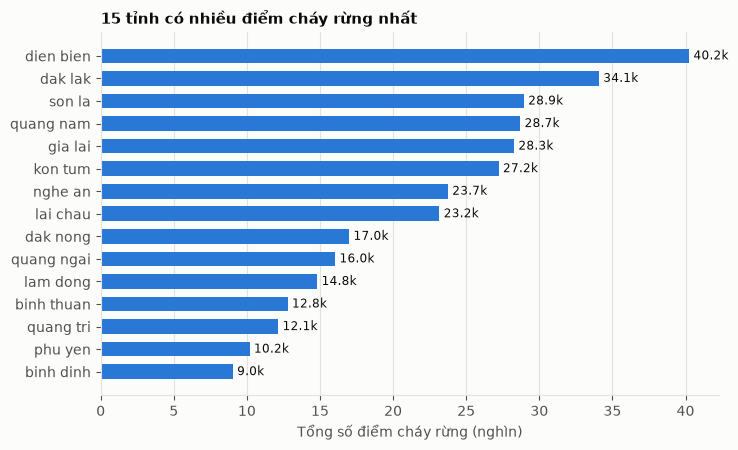

In [3]:
top = df.groupby("prov")["n_hot_forest"].sum().sort_values(ascending=False).head(15)[::-1]

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(top.index, top.values / 1000, color=BLUE, height=0.65)
for y, value in enumerate(top.values / 1000):
    ax.text(value + 0.3, y, f"{value:.1f}k", va="center", fontsize=8.5, color=INK)
ax.set_xlabel("Tổng số điểm cháy rừng (nghìn)")
ax.set_title("15 tỉnh có nhiều điểm cháy rừng nhất")
ax.grid(axis="y", visible=False)
plt.tight_layout()

print("Tổng điểm cháy rừng trong bảng dev:", int(df["n_hot_forest"].sum()))
print("15 tỉnh đầu chiếm %.0f%% tổng điểm cháy rừng" % (100 * top.sum() / df["n_hot_forest"].sum()))

,Tây Bắc,Đông Bắc,Bắc Trung Bộ,Nam Trung Bộ,Tây Nguyên,Đông Nam Bộ,ĐB sông Hồng,ĐB sông Cửu Long
tháng đỉnh,3.0,12.0,4.0,4.0,3.0,3.0,12.0,3.0
% đỉnh,63.0,32.0,56.0,66.0,95.0,48.0,5.0,14.0


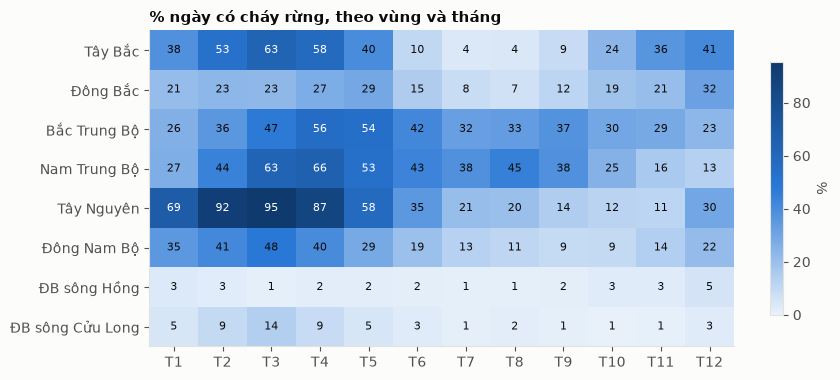

In [4]:
monthly = df.pivot_table(index="region", columns="month", values="fire_any_forest", aggfunc="mean").reindex(ALL_REGIONS) * 100

fig, ax = plt.subplots(figsize=(9, 3.9))
im = ax.imshow(monthly.values, cmap=SEQ, aspect="auto", vmin=0, vmax=monthly.values.max())
ax.set_xticks(range(12))
ax.set_xticklabels([f"T{i}" for i in range(1, 13)])
ax.set_yticks(range(len(monthly)))
ax.set_yticklabels([VN[k] for k in monthly.index])
ax.grid(False)
for i in range(monthly.shape[0]):
    for j in range(monthly.shape[1]):
        value = monthly.values[i, j]
        ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=8, color="white" if value > 0.55 * monthly.values.max() else INK)
ax.set_title("% ngày có cháy rừng, theo vùng và tháng")
plt.colorbar(im, ax=ax, shrink=0.8, label="%")
plt.tight_layout()

peak = monthly.idxmax(axis=1).rename("tháng đỉnh").to_frame()
peak["% đỉnh"] = monthly.max(axis=1).round(0)
peak.index = [VN[k] for k in peak.index]
peak.T

Năm cao nhất mỗi vùng: {'TB': 2019, 'DB': 2016, 'BTB': 2015, 'NTB': 2015, 'TN': 2015, 'DNB': 2015}


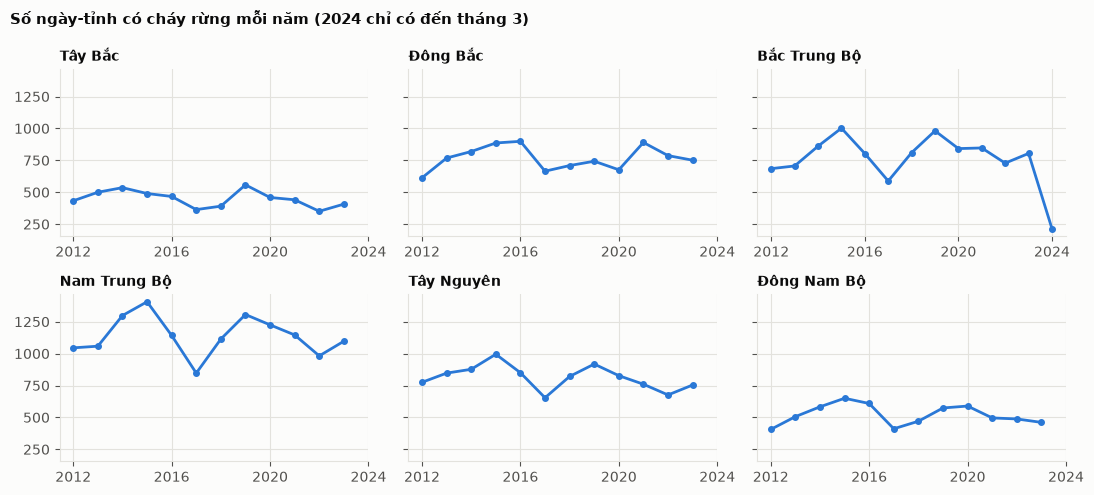

In [5]:
yearly = df[df["region"].isin(FOREST)].groupby(["region", "year"])["fire_any_forest"].sum().unstack("region")[FOREST]

fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharey=True)
for ax, key in zip(axes.ravel(), FOREST):
    ax.plot(yearly.index, yearly[key], color=BLUE, lw=2, marker="o", ms=4)
    ax.set_title(VN[key], fontsize=10)
    ax.set_xticks([2012, 2016, 2020, 2024])
fig.suptitle("Số ngày-tỉnh có cháy rừng mỗi năm (2024 chỉ có đến tháng 3)", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
print("Năm cao nhất mỗi vùng:", yearly.idxmax().to_dict())

Theo tỉ lệ ngày có cháy, Tây Nguyên đỉnh vào tháng 3 (95% số ngày có cháy), Tây Bắc tháng 3 (63%), Đông Nam Bộ tháng 3 (48%), Nam Trung Bộ và Bắc Trung Bộ tháng 4 (66% và 56%). Đông Bắc đỉnh vào tháng 12 (32%) và giữ mức cao suốt tháng 1 đến 5. Hai vùng miền Trung còn giữ mức nền cao (30 đến 45%) giữa năm nên mùa kéo dài hơn. Đồng bằng sông Hồng chỉ 1 đến 5% quanh năm, không có mùa cháy rõ. Năm 2015 (El Niño mạnh) nhiều cháy nhất ở 4/6 vùng (BTB, NTB, TN, DNB). Mùa mặc định trong dữ liệu (season) là mùa tạm theo vùng, cần thay bằng mùa trong văn bản pháp lý khi có.

,T13,D13_hpa,rain_30d,P_primary
nhan,,,,
Có cháy,30.4,18.3,53.9,2018.7
Không cháy,27.2,10.3,83.8,408.4


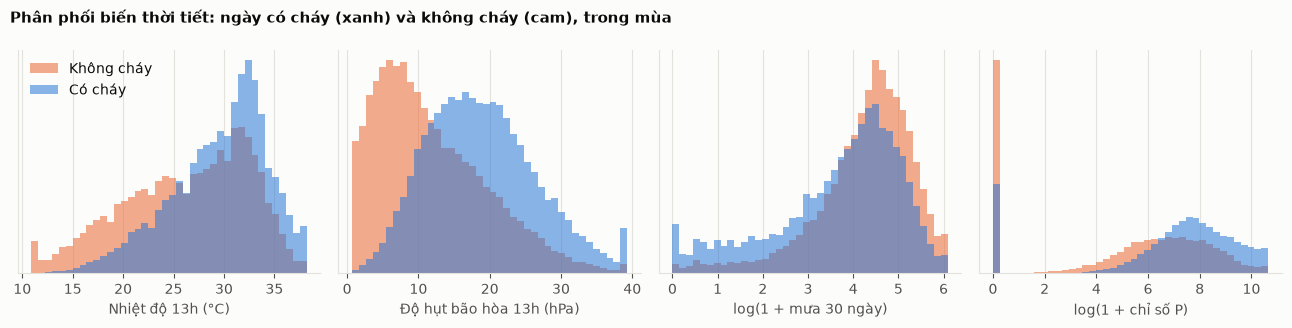

In [6]:
model = df[df["use_for_model"] == 1].copy()
model["nhan"] = np.where(model["fire_any_forest"] == 1, "Có cháy", "Không cháy")

panels = [
    ("T13", "Nhiệt độ 13h (°C)"),
    ("D13_hpa", "Độ hụt bão hòa 13h (hPa)"),
    ("log_rain_30d", "log(1 + mưa 30 ngày)"),
    ("logP", "log(1 + chỉ số P)"),
]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for ax, (column, label) in zip(axes, panels):
    lo, hi = model[column].quantile([0.005, 0.995])
    for name, color in [("Không cháy", ORANGE), ("Có cháy", BLUE)]:
        values = model.loc[model["nhan"] == name, column].clip(lo, hi)
        ax.hist(values, bins=40, density=True, histtype="stepfilled", alpha=0.55, color=color, label=name, linewidth=0)
    ax.set_xlabel(label)
    ax.set_yticks([])
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Phân phối biến thời tiết: ngày có cháy (xanh) và không cháy (cam), trong mùa", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()

model.groupby("nhan")[["T13", "D13_hpa", "rain_30d", "P_primary"]].median().round(1)

In [7]:
WEATHER = ["T13", "D13_hpa", "rain_30d", "P_primary"]
medians = model.groupby(["region", "nhan"])[WEATHER].median().unstack("nhan")
diff = pd.DataFrame({c: medians[(c, "Có cháy")] - medians[(c, "Không cháy")] for c in WEATHER}).round(1).reindex(FOREST)
diff.index = [VN[k] for k in diff.index]
print("Chênh lệch trung vị (có cháy − không cháy), theo vùng")
diff

Chênh lệch trung vị (có cháy − không cháy), theo vùng


,T13,D13_hpa,rain_30d,P_primary
Tây Bắc,4.8,6.9,-7.4,1455.8
Đông Bắc,2.8,6.2,-13.2,1042.7
Bắc Trung Bộ,2.5,7.9,-40.7,988.0
Nam Trung Bộ,1.6,5.9,-56.0,1390.8
Tây Nguyên,2.9,7.8,-60.8,4599.7
Đông Nam Bộ,0.8,3.6,-25.8,4053.6


Chênh lệch lớn nhất giữa các vùng ở cùng một mức P (điểm %):


Pbin,<100,100–300,300–500,500–1k,1k–2k,2k–4k,>4k
max−min,37.0,42.0,42.0,34.0,33.0,33.0,52.0


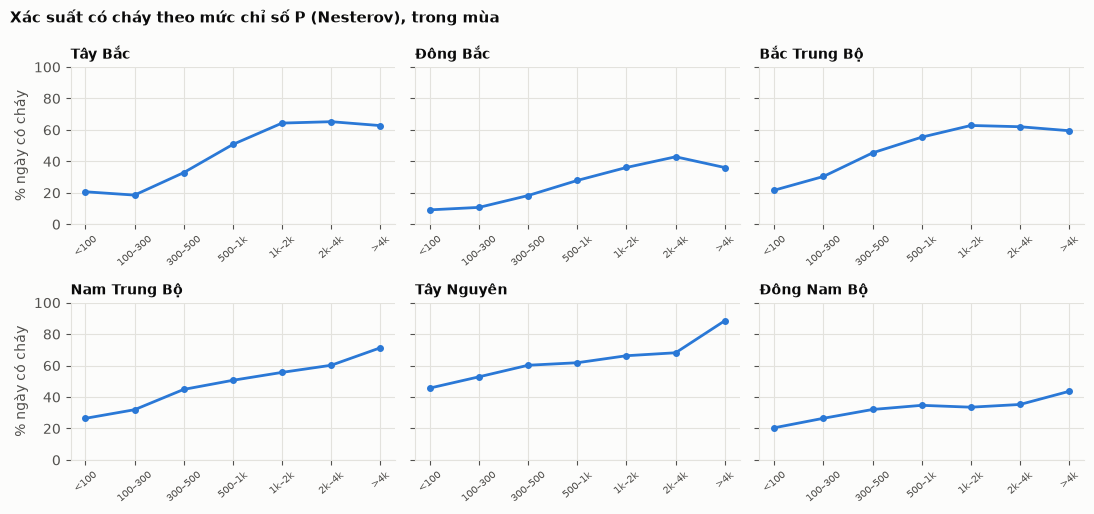

In [8]:
edges = [-1, 100, 300, 500, 1000, 2000, 4000, 1e9]
labels = ["<100", "100–300", "300–500", "500–1k", "1k–2k", "2k–4k", ">4k"]
model["Pbin"] = pd.cut(model["P_primary"], edges, labels=labels)
by_bin = model.pivot_table(index="Pbin", columns="region", values="fire_any_forest", aggfunc="mean", observed=True)[FOREST] * 100

fig, axes = plt.subplots(2, 3, figsize=(11, 5.2), sharey=True)
for ax, key in zip(axes.ravel(), FOREST):
    ax.plot(range(len(labels)), by_bin[key].values, color=BLUE, lw=2, marker="o", ms=4)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=7.5, rotation=40)
    ax.set_title(VN[key], fontsize=10)
    ax.set_ylim(0, 100)
for ax in axes[:, 0]:
    ax.set_ylabel("% ngày có cháy")
fig.suptitle("Xác suất có cháy theo mức chỉ số P (Nesterov), trong mùa", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()

spread = (by_bin.max(axis=1) - by_bin.min(axis=1)).round(0)
print("Chênh lệch lớn nhất giữa các vùng ở cùng một mức P (điểm %):")
spread.to_frame("max−min").T

Cùng một mức P nhưng xác suất cháy khác nhau rất xa giữa các vùng (P < 100: Đông Bắc khoảng 9%, Tây Nguyên khoảng 46%). Ở Tây Bắc, Đông Bắc và Bắc Trung Bộ, đường cong tăng rồi phẳng sau khoảng P = 1000 đến 2000, tức mức cảnh báo cao hơn không phân biệt thêm. Đây chỉ là mô tả; kiểm định và đánh giá ngoài mẫu nằm ở docs/ket_qua_phan_tich_dev.xlsx.

,RH13,D13_hpa,D13_anom,logP,T13_anom,rain_7d,dsr_5,rain_cal,T13,rain_30d,rep_elev_m,forest_share,oni_lag3
ρ với fire_any_forest,-0.46,0.42,0.37,0.32,0.31,-0.27,0.26,-0.26,0.25,-0.21,0.19,-0.05,0.05


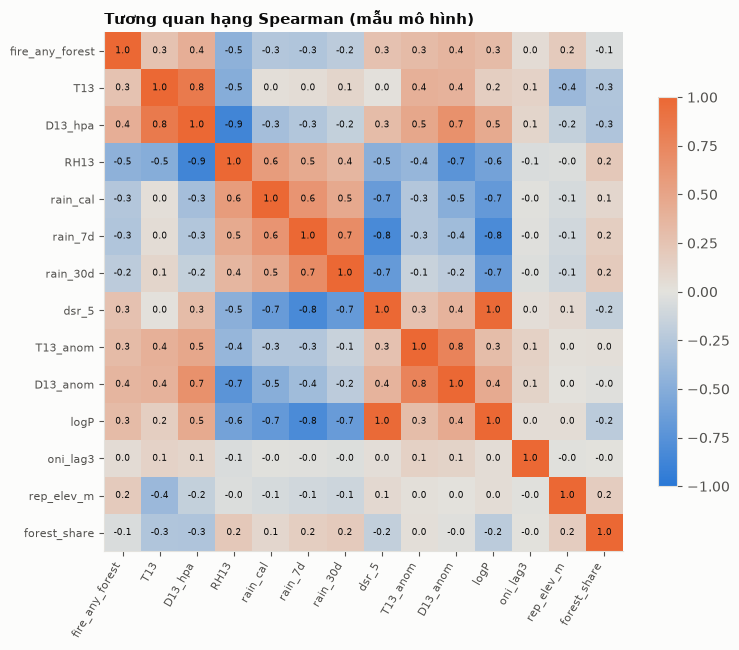

In [9]:
columns = [
    "fire_any_forest", "T13", "D13_hpa", "RH13", "rain_cal", "rain_7d", "rain_30d", "dsr_5",
    "T13_anom", "D13_anom", "logP", "oni_lag3", "rep_elev_m", "forest_share",
]
corr = model[columns].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8.2, 6.6))
im = ax.imshow(corr.values, cmap=DIV, vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(columns)))
ax.set_xticklabels(columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(columns)))
ax.set_yticklabels(columns, fontsize=8)
for i in range(len(columns)):
    for j in range(len(columns)):
        ax.text(j, i, f"{corr.values[i, j]:.1f}", ha="center", va="center", fontsize=6.5, color=INK)
ax.set_title("Tương quan hạng Spearman (mẫu mô hình)")
plt.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout()

corr["fire_any_forest"].drop("fire_any_forest").sort_values(key=abs, ascending=False).round(2).to_frame("ρ với fire_any_forest").T

Biến tương quan mạnh nhất với cháy là độ ẩm tương đối 13h (ρ khoảng −0,46) và độ hụt bão hòa 13h (+0,42), sau đó là độ lệch độ hụt so với trung bình (D13_anom, +0,37), log chỉ số P (+0,32) và độ lệch nhiệt (+0,31). Mưa 30 ngày chỉ −0,21. Các biến này tương quan mạnh với nhau (nhiệt, độ hụt, độ ẩm, P) nên có đa cộng tuyến; 26 biến thể P đã được giảm xuống 5 ở notebook 03, và khi mô hình hóa tuyến tính nên chọn một biến đại diện.

In [10]:
CALENDAR_FLAGS = {
    "Cuối tuần": "is_weekend",
    "Tết (±3 ngày)": "tet_win3",
    "Giỗ Tổ (±1 ngày)": "giotuo_win1",
    "Thanh minh (4–6/4)": "thanh_minh_win1",
}


def fire_rate(mask):
    return model.loc[mask, "fire_any_forest"].mean() * 100


calendar = pd.DataFrame(
    {
        name: (fire_rate(model[flag] == 1), fire_rate(model[flag] == 0), int((model[flag] == 1).sum()))
        for name, flag in CALENDAR_FLAGS.items()
    },
    index=["ngày đặc biệt (%)", "ngày thường (%)", "n ngày đặc biệt"],
).T
calendar[["ngày đặc biệt (%)", "ngày thường (%)"]] = calendar[["ngày đặc biệt (%)", "ngày thường (%)"]].round(1)
calendar["n ngày đặc biệt"] = calendar["n ngày đặc biệt"].astype(int)
print("Tỉ lệ ngày có cháy (thô, chưa kiểm soát thời tiết và mùa):")
calendar

Tỉ lệ ngày có cháy (thô, chưa kiểm soát thời tiết và mùa):


,ngày đặc biệt (%),ngày thường (%),n ngày đặc biệt
Cuối tuần,41.3,42.4,24109
Tết (±3 ngày),39.8,42.2,2618
Giỗ Tổ (±1 ngày),55.2,41.9,1326
Thanh minh (4–6/4),53.1,41.9,1338


Cuối tuần (41,3% so với 42,4%) và Tết (39,8% so với 42,2%) không khác đáng kể. Giỗ Tổ (55,2%) và Thanh minh (53,1%) cao hơn ngày thường khoảng 11 đến 13 điểm phần trăm, nhưng hai dịp này rơi vào cuối tháng 3 và tháng 4, lúc nắng nóng cuối mùa khô nên cháy vốn đã cao, vì vậy so sánh thô dễ nhầm. Sau khi kiểm soát thời tiết và mùa (sheet H4_calendar), Giỗ Tổ còn khoảng +7 điểm nhưng không vững (nhãn giả ở ngày khác cho kết quả tương tự, hiệu ứng đổi dấu giữa các năm), Thanh minh không có ý nghĩa. Chưa có bằng chứng vững về hiệu ứng ngày lễ.

Tỉnh đủ điều kiện: 46 / 63 | tỉnh ít dữ liệu nhất: {'thai binh': 1, 'nam dinh': 1, 'hung yen': 3, 'ben tre': 21, 'bac lieu': 21, 'bac ninh': 31}


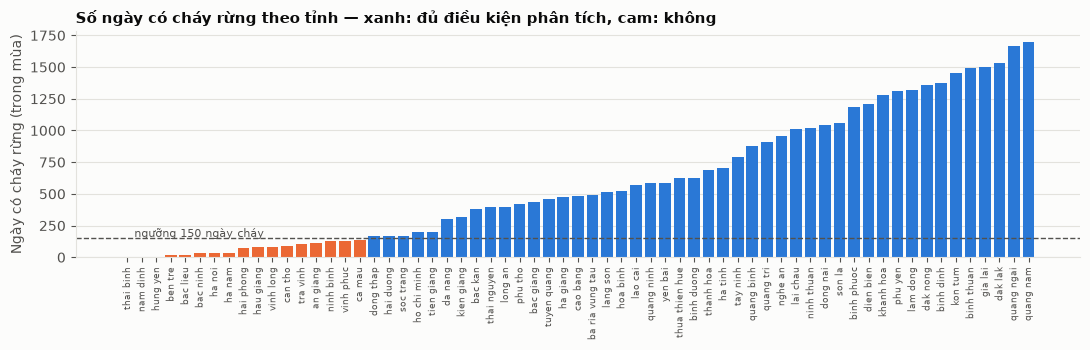

In [11]:
full_season = df[(df["in_season"] == 1) & (df["partial_season"] == 0)]
fire_days = full_season.groupby("prov")["fire_any_forest"].sum().sort_values()
eligible = full_season.groupby("prov")["eligible_prov"].first()

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(range(len(fire_days)), fire_days.values, color=[BLUE if eligible[p] == 1 else ORANGE for p in fire_days.index], width=0.8)
ax.axhline(150, color=MUTED, lw=1, ls="--")
ax.text(0.5, 160, "ngưỡng 150 ngày cháy", color=MUTED, fontsize=8)
ax.set_xticks(range(len(fire_days)))
ax.set_xticklabels(fire_days.index, rotation=90, fontsize=6.5)
ax.set_ylabel("Ngày có cháy rừng (trong mùa)")
ax.set_title("Số ngày có cháy rừng theo tỉnh — xanh: đủ điều kiện phân tích, cam: không")
ax.grid(axis="x", visible=False)
plt.tight_layout()

print("Tỉnh đủ điều kiện:", int(eligible.sum()), "/", len(eligible), "| tỉnh ít dữ liệu nhất:", fire_days.head(6).to_dict())

Kết luận:
1. Cháy rừng tập trung ở 6 vùng có rừng; hai đồng bằng (sông Hồng, sông Cửu Long) hầu như không có cháy rừng nên loại khỏi phân tích cháy rừng và giữ làm nhóm đối chứng (cháy nông nghiệp).
2. Mùa cháy rõ ở từng vùng và lệch pha nhau trong năm, nên phải chia tập kiểm tra theo mùa, không chia ngẫu nhiên.
3. Ngày có cháy nóng hơn (trung vị 30,4°C so với 27,2°C), khô hơn (độ hụt bão hòa 18,3 so với 10,3 hPa) và ít mưa tích lũy 30 ngày hơn (54 mm so với 84 mm); các biến thời tiết này tương quan mạnh với nhau nên cần giảm đa cộng tuyến trước khi mô hình hóa.
4. Cùng một mức chỉ số P, xác suất cháy khác nhau nhiều giữa các vùng và đường cong phẳng ở mức P cao, nên một thang cấp chung cho cả nước kém tin cậy.
5. Cuối tuần và Tết không khác biệt; chênh lệch thô ở Giỗ Tổ và Thanh minh phần lớn do thời điểm rơi vào cuối mùa khô, chưa có bằng chứng vững về hiệu ứng ngày lễ.
6. 17 tỉnh (chủ yếu ở đồng bằng) có quá ít ngày cháy để kiểm định riêng lẻ.